# RAG: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document under test:** *D&D Basic Rules (2018)*, Wizards of the Coast — 180
pages, ~134k words. It is distributed free by the publisher and is a rulebook
in the strict sense: general rules, then restrictions, penalties and
"except when…" clauses scattered across chapters that are often 50+ pages
apart. That separation is exactly the structure that breaks single-vector
retrieval, which makes it good material for this assignment.

**Two pipelines over one identical chunked corpus:**

| | Pipeline 1 — Baseline | Pipeline 2 — Re-Ranking |
|---|---|---|
| Stage 1 | bi-encoder, top **10** by cosine | bi-encoder, top **10** by cosine *(same 10)* |
| Stage 2 | — | cross-encoder scores all 10 `(query, chunk)` pairs |
| Context | top **3** as ranked by cosine | top **3** as ranked by the cross-encoder |
| Answer | Answer 1 | Answer 2 |

The corpus, the chunking, the candidate set and the prompt template are held
constant. The only thing that varies is **which three chunks reach the LLM**.

| Component | Model |
|---|---|
| Bi-encoder | `sentence-transformers/all-MiniLM-L6-v2` (384-d) |
| Cross-encoder | `cross-encoder/ms-marco-MiniLM-L-6-v2` |
| Generator | `gemini-3-flash-preview`, temperature 0 |

## 0. Setup

Install the dependencies (uncomment to run), then put your Gemini key in a
`.env` file next to this notebook:

```
GEMINI_API_KEY=your_key_here
```

The retrieval, re-ranking, rank-shift and latency sections all run **without**
a key. Only the two answer-generation cells need one.

In [1]:
# !pip install torch transformers sentence-transformers pymupdf google-genai \
#              numpy pandas matplotlib tqdm

import json
import os
import re
import statistics
import textwrap
import time
import urllib.request
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# ----------------------------- configuration ------------------------------ #
PDF_URL = "https://media.wizards.com/2018/dnd/downloads/DnD_BasicRules_2018.pdf"
PDF_PATH = Path("data/raw/dnd_basic_rules_2018.pdf")

BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"
GEMINI_MODEL = "gemini-3-flash-preview"

CHUNK_SIZE = 900        # characters; ~225 word-pieces, inside MiniLM's 256 limit
CHUNK_OVERLAP = 150     # characters carried between adjacent chunks
TOP_K_RETRIEVE = 10     # candidates the bi-encoder hands downstream
TOP_N_CONTEXT = 3       # chunks that actually reach the LLM

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

np.random.seed(0)
print("config loaded")

config loaded


## 1. Corpus preparation

Three things matter here, and all three affect the comparison downstream.

**Cleaning.** Every page of this PDF carries the same copyright footer and a
running chapter header. Left in, that boilerplate appears in all ~1.1k chunks
and adds a constant vector component that flattens the differences the
bi-encoder relies on. It also wastes LLM context. So it is stripped first.

**Soft-wrap repair.** PyMuPDF returns one `\n` per *typeset line*, not per
paragraph, and hyphenates words across line breaks (`Constitu-\ntion`). Both
are repaired before chunking, otherwise the tokeniser sees `Constitu` and
`tion` as separate tokens.

**Chunk boundaries.** Chunks are packed to ~900 characters and are **not
allowed to cross a page boundary**. That costs a little packing efficiency but
keeps the page number on every chunk exact — which is what makes the page
citations in the generated answers verifiable by hand against the PDF.

In [2]:
import fitz  # PyMuPDF

# Download the rulebook once (~11 MB).
PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
if not PDF_PATH.exists():
    print("downloading rulebook ...")
    urllib.request.urlretrieve(PDF_URL, PDF_PATH)
print(f"{PDF_PATH} ({PDF_PATH.stat().st_size / 1e6:.1f} MB)")

data/raw/dnd_basic_rules_2018.pdf (11.5 MB)


In [3]:
# Printed on every single page of the source PDF -- pure noise for retrieval.
BOILERPLATE = re.compile(
    r"D&D Basic Rules \(Version 1\.0\)\. Not for resale\. "
    r"Permission granted to print and photocopy this document for personal use only\."
)
# Running header, e.g. " Chapter 8: Adventuring".
CHAPTER_HEADER = re.compile(r"^\s*(?:Part \d+\s*\|\s*)?Chapter \d+:?.*$", re.M)
PAGE_NUMBER_LINE = re.compile(r"^\s*\d{1,3}\s*$", re.M)


def page_chapter(text):
    """Read the chapter name off the page's running header, before we strip it."""
    m = re.search(r"Chapter (\d+): ([^\n]+)", text)
    return f"Chapter {m.group(1)}: {m.group(2).strip()}" if m else "Front matter"


def clean_page(text):
    text = BOILERPLATE.sub("", text)
    text = CHAPTER_HEADER.sub("", text)
    text = PAGE_NUMBER_LINE.sub("", text)
    text = text.replace("\t", " ")
    # Rejoin words hyphenated across a line break ("Constitu-\ntion").
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)
    # A single newline is a soft wrap inside a paragraph -> space.
    # A blank line is a real paragraph break -> keep it.
    text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)
    text = re.sub(r"[  ]{2,}", " ", text)
    return re.sub(r"\n{3,}", "\n\n", text).strip()


def extract_pages(pdf_path=PDF_PATH):
    doc = fitz.open(pdf_path)
    pages = [
        {
            "page": i + 1,  # 1-based, matches what a PDF viewer shows
            "chapter": page_chapter(p.get_text("text")),
            "text": clean_page(p.get_text("text")),
        }
        for i, p in enumerate(doc)
    ]
    doc.close()
    return pages


pages = extract_pages()
print(f"{len(pages)} pages extracted")
print(f"\nexample -- page 46, after cleaning:\n{pages[45]['text'][:300]}")

180 pages extracted

example -- page 46, after cleaning:
Stealth. If the Armor table shows “Disadvantage” in the Stealth column, the wearer has disadvantage on Dexterity (Stealth) checks. Shields. A shield is made from wood or metal and is carried in one hand. Wielding a shield increases your Armor Class by 2. You can benefit from only one shield at a tim


In [4]:
def tail_words(text, overlap):
    """Last <=`overlap` chars of `text`, trimmed to a word boundary.

    Slicing on a raw character count leaves chunks that begin mid-word
    ("eted by a black pudding"), which is noise in the embedding and in the
    context handed to the LLM.
    """
    if overlap <= 0 or not text:
        return ""
    tail = text[-overlap:]
    return tail if len(tail) == len(text) else tail.partition(" ")[2].strip()


def split_long_sentence(sentence, size):
    """Word-level split, for spans that contain no sentence boundary at all.

    A few table dumps in this PDF (deity lists, equipment tables) arrive as
    one unbroken span; without this they would blow past `size`.
    """
    out, cur = [], ""
    for word in sentence.split():
        if cur and len(cur) + len(word) + 1 > size:
            out.append(cur)
            cur = word
        else:
            cur = f"{cur} {word}".strip()
    if cur:
        out.append(cur)
    return out


def split_paragraph(para, size, overlap):
    """Sentence-aware split for a paragraph longer than `size`."""
    sentences = []
    for s in re.split(r"(?<=[.!?”])\s+", para):
        sentences.extend([s] if len(s) <= size else split_long_sentence(s, size))

    out, cur = [], ""
    for s in sentences:
        if cur and len(cur) + len(s) + 1 > size:
            out.append(cur.strip())
            cur = f"{tail_words(cur, overlap)} {s}".strip()  # carry context over
        else:
            cur = f"{cur} {s}".strip()
    if cur.strip():
        out.append(cur.strip())
    return out


def chunk_pages(pages, size=CHUNK_SIZE, overlap=CHUNK_OVERLAP, min_chars=120):
    """Pack paragraphs into ~`size`-char chunks, never crossing a page."""
    chunks = []
    for p in pages:
        buf, pieces = "", []
        for para in [x.strip() for x in p["text"].split("\n") if x.strip()]:
            if len(para) > size:
                if buf:
                    pieces.append(buf)
                    buf = ""
                pieces.extend(split_paragraph(para, size, overlap))
            elif buf and len(buf) + len(para) + 1 > size:
                pieces.append(buf)
                buf = para
            else:
                buf = f"{buf} {para}".strip()
        if buf:
            pieces.append(buf)

        for piece in pieces:
            if len(piece) < min_chars:   # stray captions, table headers
                continue
            chunks.append(
                {
                    "chunk_id": len(chunks),
                    "page": p["page"],
                    "chapter": p["chapter"],
                    "text": piece,
                    "n_chars": len(piece),
                }
            )
    return chunks


chunks = chunk_pages(pages)
lengths = [c["n_chars"] for c in chunks]
print(f"chunks       : {len(chunks)}")
print(f"chars/chunk  : mean {statistics.mean(lengths):.0f} | "
      f"min {min(lengths)} | max {max(lengths)}")
print(f"total chars  : {sum(lengths):,}")
print(f"chapters seen: {len({c['chapter'] for c in chunks})}")

Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("data/processed/chunks.json").write_text(json.dumps(chunks, ensure_ascii=False))
pd.DataFrame(chunks).head(3)[["chunk_id", "page", "chapter", "n_chars"]]

chunks       : 1119
chars/chunk  : mean 774 | min 121 | max 1049
total chars  : 866,320
chapters seen: 15


,chunk_id,page,chapter,n_chars
0,0,1,Front matter,225
1,1,1,Front matter,1037
2,2,1,Front matter,874


## 2. Stage 1 — the bi-encoder index

A **bi-encoder** embeds the query and each chunk *independently* into the same
vector space; relevance is then the cosine between two vectors that were
computed without ever seeing each other. Because chunk vectors do not depend
on the query, all ~1.1k of them are embedded once, up front, and reused for
every query. That is what makes this stage cheap enough to scan the whole
corpus.

Embeddings are L2-normalised, so a plain dot product **is** cosine similarity.

The index is an exact (flat) scan rather than an approximate one (HNSW/IVF).
At this corpus size an exact scan is instant, and it matters for the analysis:
any retrieval miss observed below is attributable to the embedding model, not
to approximation error in the index.

In [5]:
from sentence_transformers import SentenceTransformer


@dataclass
class Hit:
    """One retrieved chunk, with the rank it held in the stage that produced it."""
    chunk_id: int
    page: int
    chapter: str
    text: str
    score: float
    rank: int                  # 1-based, in the producing stage
    baseline_rank: int = None  # where the bi-encoder had put it


@dataclass
class StageTiming:
    embed_query_ms: float = 0.0
    vector_search_ms: float = 0.0
    cross_encode_ms: float = 0.0
    llm_ms: float = 0.0

    @property
    def retrieval_ms(self):
        """Everything before the LLM -- the only part the pipelines differ in."""
        return self.embed_query_ms + self.vector_search_ms + self.cross_encode_ms


class DenseIndex:
    """Exact inner-product index over L2-normalised chunk embeddings."""

    def __init__(self, chunks, model_name=BI_ENCODER_NAME):
        self.chunks = chunks
        self.model = SentenceTransformer(model_name)
        self.embeddings = None

    def build(self, cache=Path("data/processed/embeddings.npy"), batch_size=64):
        """Embed every chunk once. Returns seconds spent indexing."""
        if cache and cache.exists():
            cached = np.load(cache)
            if cached.shape[0] == len(self.chunks):
                self.embeddings = cached
                print(f"loaded cached embeddings {cached.shape}")
                return 0.0

        t0 = time.perf_counter()
        self.embeddings = self.model.encode(
            [c["text"] for c in self.chunks],
            batch_size=batch_size,
            normalize_embeddings=True,   # so dot product == cosine
            convert_to_numpy=True,
            show_progress_bar=True,
        ).astype(np.float32)
        elapsed = time.perf_counter() - t0
        if cache:
            np.save(cache, self.embeddings)
        return elapsed

    def search(self, query, k=TOP_K_RETRIEVE):
        t = StageTiming()

        t0 = time.perf_counter()
        q = self.model.encode([query], normalize_embeddings=True,
                              convert_to_numpy=True)
        t.embed_query_ms = (time.perf_counter() - t0) * 1000

        t0 = time.perf_counter()
        scores = (self.embeddings @ q[0]).astype(np.float32)
        # argpartition isolates the top k in O(n); only those k get sorted.
        top = np.argpartition(-scores, k)[:k]
        top = top[np.argsort(-scores[top])]
        t.vector_search_ms = (time.perf_counter() - t0) * 1000

        hits = []
        for rank, idx in enumerate(top, start=1):
            c = self.chunks[int(idx)]
            hits.append(Hit(c["chunk_id"], c["page"], c["chapter"], c["text"],
                            float(scores[idx]), rank, rank))
        return hits, t


index = DenseIndex(chunks)
build_seconds = index.build()
print(f"index: {index.embeddings.shape[0]} vectors x {index.embeddings.shape[1]} dims "
      f"| built in {build_seconds:.1f}s (0.0 = from cache)")

/Users/deeptikoranga/Downloads/lma/lma1/rag_assignment/.venv/lib/python3.9/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:13: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange
/Users/deeptikoranga/Downloads/lma/lma1/rag_assignment/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


loaded cached embeddings (1119, 384)
index: 1119 vectors x 384 dims | built in 0.0s (0.0 = from cache)


## 3. Pipeline 1 — baseline retrieval

Retrieve the top 10 by cosine, then hand the **first 3** to the LLM unchanged.

The demo query is a worked example of the keyword trap. The rulebook contains
two things that answer to the name "two-weapon fighting":

* a **Fighter class feature titled "Two-Weapon Fighting"** on p.27, which only
  adds an ability modifier to the damage of the second attack, and
* the **actual rule** on p.77, fifty pages later, which is what says you may do
  it at all — and that both weapons must have the *light* property.

The heading on p.27 is a near-exact lexical match for the question. The rule on
p.77 is not. Watch where each one lands.

In [6]:
DEMO_QUERY = "Can I attack with a weapon in each hand on the same turn?"


def show_hits(hits, title, highlight=()):
    """Render a ranking as a table; `highlight` marks the answer-bearing chunks."""
    rows = []
    for h in hits:
        rows.append(
            {
                "rank": h.rank,
                "from": h.baseline_rank if h.baseline_rank != h.rank else "",
                "gold": "***" if h.chunk_id in highlight else "",
                "score": round(h.score, 4),
                "chunk": h.chunk_id,
                "page": h.page,
                "chapter": h.chapter.replace("Chapter ", "ch."),
                "preview": " ".join(h.text.split())[:88],
            }
        )
    print(f"--- {title} ---")
    return pd.DataFrame(rows).set_index("rank")


candidates, base_timing = index.search(DEMO_QUERY, k=TOP_K_RETRIEVE)

# The rule that answers the query is the two-weapon fighting rule on page 77,
# identified by a phrase that appears nowhere else in the book.
GOLD_DEMO = {c["chunk_id"] for c in chunks
             if "different light melee weapon" in c["text"]}
print(f"query: {DEMO_QUERY}")
print(f"answer-bearing chunk(s): {sorted(GOLD_DEMO)}\n")
show_hits(candidates, "Pipeline 1: bi-encoder top 10", GOLD_DEMO)

query: Can I attack with a weapon in each hand on the same turn?
answer-bearing chunk(s): [549]

--- Pipeline 1: bi-encoder top 10 ---


,from,gold,score,chunk,page,chapter,preview
rank,,,,,,,
1,,,0.4027,193,27,ch.3: Classes,"Two-Weapon Fighting When you engage in two-weapon fighting, you can add your ability mod"
2,,,0.3894,550,77,ch.9: Combat,"unless that modifier is negative. If either weapon has the thrown property, you can thro"
3,,,0.3808,197,27,ch.3: Classes,or (b) two handaxes • (a) a dungeoneer’s pack or (b) an explorer’s pack Fighting Style Y
4,,,0.3750,528,74,ch.9: Combat,"with your fists. With this action, you make one melee or ranged attack. See the “Making"
5,,***,0.3535,549,77,ch.9: Combat,modifier—the same modifier used for the attack roll—to the damage. A spell tells you whi
6,,,0.3527,967,149,ch.12: Monsters,Multiattack. The bear makes two attacks: one with its bite and one with its claws. Bite.
7,,,0.3435,516,73,ch.9: Combat,Other Activity on Your Turn Your turn can include a variety of flourishes that require n
8,,,0.3365,337,48,ch.5: Equipment,for a Small creature to use effectively. Light. A light weapon is small and easy to hand
9,,,0.3307,544,76,ch.9: Combat,also involve making a melee attack. Most creatures have a 5-foot reach and can thus atta


In [7]:
baseline_context = candidates[:TOP_N_CONTEXT]
print("Chunks that Pipeline 1 sends to the LLM:")
for h in baseline_context:
    mark = "  <-- answers the question" if h.chunk_id in GOLD_DEMO else ""
    print(f"\n[rank {h.rank}] chunk {h.chunk_id}, page {h.page}{mark}")
    print(textwrap.fill(" ".join(h.text.split())[:300], 96, initial_indent="    ",
                        subsequent_indent="    "))

Chunks that Pipeline 1 sends to the LLM:

[rank 1] chunk 193, page 27
    Two-Weapon Fighting When you engage in two-weapon fighting, you can add your ability
    modifier to the damage of the second attack. Second Wind You have a limited well of stamina
    that you can draw on to protect yourself from harm. On your turn, you can use a bonus action
    to regain hit points equal to

[rank 2] chunk 550, page 77
    unless that modifier is negative. If either weapon has the thrown property, you can throw
    the weapon, instead of making a melee attack with it. Grappling When you want to grab a
    creature or wrestle with it, you can use the Attack action to make a special melee attack, a
    grapple. If you’re able to ma

[rank 3] chunk 197, page 27
    or (b) two handaxes • (a) a dungeoneer’s pack or (b) an explorer’s pack Fighting Style You
    adopt a particular style of fighting as your specialty. Choose one of the following options.
    You can’t take a Fighting Style option more

## 4. Stage 2 — the cross-encoder re-ranker

A **cross-encoder** takes a different shape of input: the query and the chunk
are concatenated into *one* sequence, `[CLS] query [SEP] chunk [SEP]`, and run
through the transformer together. Every query token can attend to every chunk
token and vice versa, and the model emits a single relevance score. There is
no chunk vector to cache — the score only exists for that specific pair — so
the cost is one full forward pass **per pair**.

That is why it is a second stage and not the first: here it runs on 10 pairs,
not 1,118.

In [8]:
from sentence_transformers import CrossEncoder


class Reranker:
    """Scores each (query, chunk) pair jointly, then re-sorts the candidates."""

    def __init__(self, model_name=CROSS_ENCODER_NAME):
        self.model = CrossEncoder(model_name)

    def rerank(self, query, candidates):
        t0 = time.perf_counter()
        scores = self.model.predict([(query, h.text) for h in candidates],
                                    show_progress_bar=False)
        elapsed_ms = (time.perf_counter() - t0) * 1000

        reranked = []
        for new_rank, i in enumerate(np.argsort(-np.asarray(scores)), start=1):
            src = candidates[int(i)]
            # baseline_rank is carried through, so every row records where the
            # bi-encoder had put this chunk.
            reranked.append(Hit(src.chunk_id, src.page, src.chapter, src.text,
                                float(scores[int(i)]), new_rank, src.baseline_rank))
        return reranked, elapsed_ms


reranker = Reranker()
reranked, cross_ms = reranker.rerank(DEMO_QUERY, candidates)
print(f"scored {len(candidates)} pairs in {cross_ms:.0f} ms\n")
show_hits(reranked, "Pipeline 2: after cross-encoder re-ranking", GOLD_DEMO)

scored 10 pairs in 244 ms

--- Pipeline 2: after cross-encoder re-ranking ---


,from,gold,score,chunk,page,chapter,preview
rank,,,,,,,
1,5,***,2.1195,549,77,ch.9: Combat,modifier—the same modifier used for the attack roll—to the damage. A spell tells you whi
2,1,,1.5770,193,27,ch.3: Classes,"Two-Weapon Fighting When you engage in two-weapon fighting, you can add your ability mod"
3,7,,1.4452,516,73,ch.9: Combat,Other Activity on Your Turn Your turn can include a variety of flourishes that require n
4,2,,-0.8432,550,77,ch.9: Combat,"unless that modifier is negative. If either weapon has the thrown property, you can thro"
5,10,,-1.9077,527,74,ch.9: Combat,it has disadvantage on attack rolls and Dexterity saving throws. Attack rolls against th
6,3,,-2.3012,197,27,ch.3: Classes,or (b) two handaxes • (a) a dungeoneer’s pack or (b) an explorer’s pack Fighting Style Y
7,9,,-3.8059,544,76,ch.9: Combat,also involve making a melee attack. Most creatures have a 5-foot reach and can thus atta
8,,,-4.4192,337,48,ch.5: Equipment,for a Small creature to use effectively. Light. A light weapon is small and easy to hand
9,6,,-7.0064,967,149,ch.12: Monsters,Multiattack. The bear makes two attacks: one with its bite and one with its claws. Bite.


In [9]:
# Side-by-side: same 10 candidates, two orderings.
comparison = pd.DataFrame(
    {
        "baseline_rank": [h.baseline_rank for h in reranked],
        "reranked_rank": [h.rank for h in reranked],
        "shift": [h.baseline_rank - h.rank for h in reranked],
        "chunk": [h.chunk_id for h in reranked],
        "page": [h.page for h in reranked],
        "cross_score": [round(h.score, 3) for h in reranked],
        "answers_query": [h.chunk_id in GOLD_DEMO for h in reranked],
    }
).set_index("reranked_rank")
comparison

,baseline_rank,shift,chunk,page,cross_score,answers_query
reranked_rank,,,,,,
1,5,4,549,77,2.119,True
2,1,-1,193,27,1.577,False
3,7,4,516,73,1.445,False
4,2,-2,550,77,-0.843,False
5,10,5,527,74,-1.908,False
6,3,-3,197,27,-2.301,False
7,9,2,544,76,-3.806,False
8,8,0,337,48,-4.419,False
9,6,-3,967,149,-7.006,False


## 5. Generation — one prompt template, two contexts

The prompt is fixed. Both pipelines fill the same template with three
numbered passages; only the passages differ. The instructions deliberately
ask for exceptions and restrictions and for a page citation per rule, because
those are what a missing chunk causes the model to get wrong — and a cited
page number is something we can check against the PDF by hand.

`temperature=0` so that the same context always yields the same answer, and
any difference between Answer 1 and Answer 2 is attributable to the retrieved
context rather than to sampling noise.

In [10]:
PROMPT_TEMPLATE = """You are answering questions about a tabletop game rulebook.
Use ONLY the numbered context passages below. Do not use outside knowledge.

Rules for your answer:
- If the passages do not contain the answer, reply exactly: NOT IN CONTEXT.
- State any exception, restriction or penalty that the passages mention.
- Cite the page number for each rule you state, like (p. 46).
- Answer in at most 120 words.

CONTEXT
{context}

QUESTION
{query}

ANSWER"""


def build_prompt(query, context):
    """Identical template for both pipelines; only `context` differs."""
    blocks = [
        f"[{i}] (page {h.page} | {h.chapter})\n{h.text}"
        for i, h in enumerate(context, start=1)
    ]
    return PROMPT_TEMPLATE.format(context="\n\n".join(blocks), query=query)


def load_env(path=Path(".env")):
    """Minimal .env reader, so the key is never pasted into a cell."""
    if not path.exists():
        return
    for line in path.read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            k, _, v = line.partition("=")
            os.environ.setdefault(k.strip(), v.strip().strip("'\""))


class GeminiGenerator:
    def __init__(self, model=GEMINI_MODEL):
        from google import genai

        load_env()
        key = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
        if not key:
            raise RuntimeError("no GEMINI_API_KEY -- put it in .env")
        self.client = genai.Client(api_key=key)
        self.model = model

    def generate(self, prompt, attempts=6):
        """Generate, retrying on the transient errors the free tier throws.

        429 (quota) and 503 (model busy) are routine and would otherwise abort
        a multi-query run part-way. Only the successful call is timed, so
        retries never contaminate the latency figures.
        """
        from google.genai import types

        config = types.GenerateContentConfig(
            temperature=0.0,   # same context must give the same answer
            max_output_tokens=2048,
            thinking_config=types.ThinkingConfig(thinking_budget=0),
        )
        for attempt in range(attempts):
            try:
                t0 = time.perf_counter()
                resp = self.client.models.generate_content(
                    model=self.model, contents=prompt, config=config
                )
                return (resp.text or "").strip(), (time.perf_counter() - t0) * 1000
            except Exception as e:
                transient = any(c in str(e) for c in ("429", "503", "500", "UNAVAILABLE"))
                if not transient or attempt == attempts - 1:
                    raise
                time.sleep(2 ** attempt * 4)   # 4s, 8s, 16s, 32s, 64s


# The notebook stays runnable without a key: retrieval, rank shifts and
# latency are all key-free. Only this generator needs one.
try:
    generator = GeminiGenerator()
    print(f"generator ready: {GEMINI_MODEL}")
except RuntimeError as e:
    generator = None
    print(f"!! {e}\n   Answer cells will be skipped; everything else still runs.")


# Generated answers are cached to results/. Re-executing the notebook then
# costs no API calls and survives the free tier's 20-requests-per-day cap,
# and a reader without a key still sees the answers from the recorded run.
FORCE_REGENERATE = False


def load_cache(name):
    path = RESULTS / name
    if FORCE_REGENERATE or not path.exists():
        return None
    try:
        return json.loads(path.read_text())
    except Exception:
        return None

print(build_prompt(DEMO_QUERY, baseline_context)[:700])

generator ready: gemini-3-flash-preview
You are answering questions about a tabletop game rulebook.
Use ONLY the numbered context passages below. Do not use outside knowledge.

Rules for your answer:
- If the passages do not contain the answer, reply exactly: NOT IN CONTEXT.
- State any exception, restriction or penalty that the passages mention.
- Cite the page number for each rule you state, like (p. 46).
- Answer in at most 120 words.

CONTEXT
[1] (page 27 | Chapter 3: Classes)
Two-Weapon Fighting When you engage in two-weapon fighting, you can add your ability modifier to the damage of the second attack. Second Wind You have a limited well of stamina that you can draw on to protect yourself from harm. On your turn, you can use


/Users/deeptikoranga/Downloads/lma/lma1/rag_assignment/.venv/lib/python3.9/site-packages/google/auth/__init__.py:54: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
/Users/deeptikoranga/Downloads/lma/lma1/rag_assignment/.venv/lib/python3.9/site-packages/google/oauth2/__init__.py:40: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)


In [11]:
@dataclass
class PipelineResult:
    query: str
    pipeline: str
    candidates: list = field(default_factory=list)  # all 10
    context: list = field(default_factory=list)     # the 3 sent to the LLM
    answer: str = ""
    timing: StageTiming = field(default_factory=StageTiming)


def run_baseline(query, generate=True):
    """Pipeline 1: dense top-10, take top-3 as ranked by cosine."""
    cands, t = index.search(query, k=TOP_K_RETRIEVE)
    r = PipelineResult(query, "baseline", cands, cands[:TOP_N_CONTEXT], timing=t)
    if generate and generator:
        r.answer, r.timing.llm_ms = generator.generate(build_prompt(query, r.context))
    return r


def run_reranked(query, generate=True):
    """Pipeline 2: the same dense top-10, re-sorted by the cross-encoder."""
    cands, t = index.search(query, k=TOP_K_RETRIEVE)
    rr, cross_ms = reranker.rerank(query, cands)
    t.cross_encode_ms = cross_ms
    r = PipelineResult(query, "reranked", rr, rr[:TOP_N_CONTEXT], timing=t)
    if generate and generator:
        r.answer, r.timing.llm_ms = generator.generate(build_prompt(query, r.context))
    return r


def demo_from_answers_cache(query):
    """Reuse the saved answers if this query is already one of the stress
    queries (it is -- DEMO_QUERY is Q14), so the walkthrough costs no extra
    API calls and shows exactly the same pair as the analysis below."""
    for a in load_cache("answers.json") or []:
        if a["query"] == query:
            return [
                {"tag": "ANSWER 1  (baseline)", "answer": a["answer_1_baseline"],
                 "pages": a["baseline_pages"], "chunks": a["baseline_chunks"]},
                {"tag": "ANSWER 2  (re-ranked)", "answer": a["answer_2_reranked"],
                 "pages": a["reranked_pages"], "chunks": a["reranked_chunks"]},
            ]
    return None


demo = load_cache("demo_answer.json") or demo_from_answers_cache(DEMO_QUERY)
if demo:
    print("(using cached answers -- set FORCE_REGENERATE = True to call the API)\n")
elif generator:
    try:
        a1, a2 = run_baseline(DEMO_QUERY), run_reranked(DEMO_QUERY)
        demo = [
            {"tag": "ANSWER 1  (baseline)", "answer": a1.answer,
             "pages": [h.page for h in a1.context],
             "chunks": [h.chunk_id for h in a1.context]},
            {"tag": "ANSWER 2  (re-ranked)", "answer": a2.answer,
             "pages": [h.page for h in a2.context],
             "chunks": [h.chunk_id for h in a2.context]},
        ]
        (RESULTS / "demo_answer.json").write_text(json.dumps(demo, indent=1))
    except Exception as e:
        # Quota or a busy model must not abort the whole notebook run.
        print(f"generation unavailable: {str(e)[:200]}")
else:
    print("no API key and no cached answer -- skipped")

for d in demo or []:
    print("=" * 96)
    print(f"{d['tag']}   context pages: {d['pages']}  chunks: {d['chunks']}")
    print("=" * 96)
    print(textwrap.fill(d["answer"], 96), "\n")

(using cached answers -- set FORCE_REGENERATE = True to call the API)

ANSWER 1  (baseline)   context pages: [27, 77, 27]  chunks: [193, 550, 197]
Based on the provided context, you can engage in two-weapon fighting. When doing so, you can add
your ability modifier to the damage of the second attack, unless that modifier is negative (p.
27, 77). If either weapon has the thrown property, you may throw it instead of making a melee
attack (p. 77).   Additionally, if you are at least 2nd level, you can use Action Surge to take
one additional action on your turn, which increases to two uses at 17th level (p. 27). You must
finish a short or long rest before using Action Surge again (p. 27). 

ANSWER 2  (re-ranked)   context pages: [77, 27, 73]  chunks: [549, 193, 516]
Yes, when you take the Attack action with a light melee weapon in one hand, you can use a bonus
action to attack with a different light melee weapon in the other hand (p. 77). If either weapon
has the thrown property, you may t

## 6. Failure mode analysis

### How a "failure" is measured, not asserted

For each query the chunk that genuinely answers it is identified up front, by
a regex matching a phrase unique to that chunk (`gold`). Every claim below is
then a number rather than an impression:

* `rank_100` — where the bi-encoder puts the gold chunk in a top-**100** sweep.
  This is diagnostic only, and it separates two different failures: a chunk
  sitting at rank 7 is a *ranking* problem the cross-encoder can fix; a chunk
  at rank 60 never enters the candidate set, so **re-ranking cannot help** —
  that is a recall ceiling, and it is a real limitation of this architecture.
* `base` — its rank in the top 10 that Pipeline 1 actually uses.
* `rerank` — its rank after the cross-encoder re-sorts those same 10.
* A query is **rescued** when the gold chunk was outside the top 3 for the
  baseline and inside the top 3 after re-ranking.

The queries are worded with everyday synonyms instead of the rulebook's
vocabulary, which is the mismatch a bi-encoder handles worst. `Q15` is a
deliberate **control**: it uses the rulebook's exact terminology, so the
baseline should already succeed and re-ranking should have nothing to fix.

In [12]:
QUERY_POOL = [
    # ---------------------- keyword trap / distractor ---------------------- #
    dict(qid="Q1", category="Keyword trap / distractor",
         query="Does wearing heavy plate make it harder to sneak past guards unnoticed?",
         gold=r"Stealth column",
         note="The decisive rule is in the Equipment chapter and never says 'sneak' "
              "or 'guards'. The Skills section does -- it literally reads 'slink past "
              "guards'. The query's own words point at the wrong chunk."),
    dict(qid="Q2", category="Keyword trap / distractor",
         query="How much gold per day does a comfortable standard of living cost?",
         gold=r"prices listed are per day",
         note="'Comfortable' and 'wealthy' appear throughout the personality-trait "
              "and background tables, which have nothing to do with expenses."),
    dict(qid="Q3", category="Keyword trap / distractor",
         query="What do I roll to spot an enemy trying to hide from me?",
         gold=r"contest.{0,80}Wisdom \(Perception\)|Wisdom \(Perception\) check.{0,80}contest",
         note="'Hide' and 'spot' collide with dozens of rogue features and spells."),
    dict(qid="Q14", category="Keyword trap / distractor",
         query="Can I attack with a weapon in each hand on the same turn?",
         gold=r"different light melee weapon",
         note="The Fighter class has a feature *titled* 'Two-Weapon Fighting' on p.27 "
              "that only tweaks damage. The actual rule, with its 'light weapon' "
              "restriction, is 50 pages later on p.77. The distractor wins on the "
              "heading alone."),
    # ------------------------ exceptions / corner cases -------------------- #
    dict(qid="Q4", category="Exception / corner case",
         query="If a fight comes at us in several waves, can we rest in between to heal up?",
         gold=r"between parts of a multipart encounter",
         note="The general resting rules say a short rest restores hit points. The "
              "restriction that denies it mid-encounter sits ~96 pages away, in the "
              "DM's encounter-building chapter."),
    dict(qid="Q5", category="Exception / corner case",
         query="After a full night of sleep, do I get all of my Hit Dice back?",
         gold=r"regains spent Hit Dice, up to a number of dice equal to half",
         note="The intuitive answer is 'yes, everything resets'. The actual rule grants "
              "only half, in one sentence inside a long passage about resting."),
    dict(qid="Q6", category="Exception / corner case",
         query="Can I wear a second shield on my other arm for more protection?",
         gold=r"benefit from only one shield at a time",
         note="A one-clause restriction buried in a chunk about armour types."),
    # --------------------------- negation / constraints -------------------- #
    dict(qid="Q7", category="Negation / constraint",
         query="What is a creature not allowed to do while another creature holds it in a grapple?",
         gold=r"Escaping a Grapple",
         note="Bi-encoders blur 'what you can do' and 'what you cannot do' -- both "
              "embed into much the same region."),
    dict(qid="Q8", category="Negation / constraint",
         query="What will make me lose a spell I am trying to keep going?",
         gold=r"factors can break concentration",
         note="Over a hundred spell entries carry the word 'Concentration' in their "
              "duration line, swamping the one chunk that states the rule."),
    dict(qid="Q9", category="Negation / constraint",
         query="When am I prohibited from acting at all at the start of a battle?",
         gold=r"can.t move or take an action on your first turn",
         note="Negative phrasing against a chapter full of 'you can' statements."),
    # --------------------------- buried but vital -------------------------- #
    dict(qid="Q10", category="Buried vital chunk",
         query="How long can somebody stay underwater before they start dying?",
         gold=r"rounds to reach air",
         note="Answered in the travel chapter, nowhere near combat or healing."),
    dict(qid="Q11", category="Buried vital chunk",
         query="Does scrambling up a wall or wading through a swamp slow me down?",
         gold=r"climbing, swimming, or crawling",
         note="The movement-cost rule is phrased in feet, not in 'slow down'."),
    dict(qid="Q12", category="Buried vital chunk",
         query="How far can I jump from a standing start without a run-up?",
         gold=r"make a standing long jump",
         note="Jumping sits in the travel chapter, away from the movement rules."),
    dict(qid="Q13", category="Buried vital chunk",
         query="How much damage do you take from a long drop?",
         gold=r"bludgeoning damage for every 10 feet it fell",
         note="'Damage' retrieves combat and spell text far more strongly."),
    # ------------------------------- control ------------------------------- #
    dict(qid="Q15", category="Control (baseline should succeed)",
         query="How many failed death saving throws does it take to die?",
         gold=r"third failure, you die",
         note="Control: the query uses the rulebook's exact terminology, so the "
              "bi-encoder should already rank it first."),
]

# Every gold pattern must match at least one chunk, or the query is
# unanswerable from this corpus and the measurement would be meaningless.
for q in QUERY_POOL:
    hits = [c["chunk_id"] for c in chunks if re.search(q["gold"], c["text"], re.I)]
    assert hits, f"{q['qid']}: gold pattern matches no chunk"
    q["gold_ids"] = set(hits)
print(f"{len(QUERY_POOL)} queries, all gold patterns resolved")

15 queries, all gold patterns resolved


In [13]:
DIAGNOSTIC_K = 100  # wide sweep, to tell a ranking problem from a recall ceiling


def rank_of_gold(hits, gold_ids):
    """1-based rank of the best-placed gold chunk, or None if absent."""
    return next((h.rank for h in hits if h.chunk_id in gold_ids), None)


rank_rows, detail = [], {}
for q in QUERY_POOL:
    deep, _ = index.search(q["query"], k=DIAGNOSTIC_K)
    deep_rank = rank_of_gold(deep, q["gold_ids"])

    # Pipeline 1 uses the first 10 of exactly this ranking.
    cands = deep[:TOP_K_RETRIEVE]
    for i, h in enumerate(cands, start=1):
        h.rank = h.baseline_rank = i
    rr, _ = reranker.rerank(q["query"], cands)

    base_rank, rr_rank = rank_of_gold(cands, q["gold_ids"]), rank_of_gold(rr, q["gold_ids"])
    in_base = bool(base_rank and base_rank <= TOP_N_CONTEXT)
    in_rr = bool(rr_rank and rr_rank <= TOP_N_CONTEXT)

    detail[q["qid"]] = {"candidates": cands, "reranked": rr, "q": q}
    rank_rows.append(
        {
            "qid": q["qid"],
            "category": q["category"],
            "rank_100": deep_rank,
            "base": base_rank,
            "rerank": rr_rank,
            "in_top3_base": in_base,
            "in_top3_rerank": in_rr,
            "outcome": ("rescued" if in_rr and not in_base
                        else "already ok" if in_base and in_rr
                        else "lost" if in_base and not in_rr
                        else "unreachable" if base_rank is None
                        else "still missed"),
            "gold_pages": sorted({c["page"] for c in chunks
                                  if c["chunk_id"] in q["gold_ids"]}),
        }
    )

rank_df = pd.DataFrame(rank_rows).set_index("qid")
print(rank_df["outcome"].value_counts().to_string(), "\n")
rank_df[["category", "rank_100", "base", "rerank", "in_top3_base",
         "in_top3_rerank", "outcome"]]

outcome
already ok      8
rescued         3
still missed    2
unreachable     2 



,category,rank_100,base,rerank,in_top3_base,in_top3_rerank,outcome
qid,,,,,,,
Q1,Keyword trap / distractor,6.0,6.0,7.0,False,False,still missed
Q2,Keyword trap / distractor,2.0,2.0,1.0,True,True,already ok
Q3,Keyword trap / distractor,1.0,1.0,2.0,True,True,already ok
Q14,Keyword trap / distractor,5.0,5.0,1.0,False,True,rescued
Q4,Exception / corner case,98.0,NaN,NaN,False,False,unreachable
Q5,Exception / corner case,2.0,2.0,2.0,True,True,already ok
Q6,Exception / corner case,3.0,3.0,1.0,True,True,already ok
Q7,Negation / constraint,2.0,2.0,1.0,True,True,already ok
Q8,Negation / constraint,NaN,NaN,NaN,False,False,unreachable


In [14]:
# The headline numbers for the report.
rescued = rank_df[rank_df.outcome == "rescued"]
unreachable = rank_df[rank_df.outcome == "unreachable"]

print(f"queries              : {len(rank_df)}")
print(f"gold in top 3, base  : {int(rank_df.in_top3_base.sum())}")
print(f"gold in top 3, rerank: {int(rank_df.in_top3_rerank.sum())}")
print(f"rescued by re-ranking: {len(rescued)}  {list(rescued.index)}")
print(f"beyond recall (not in top 10 at all): {len(unreachable)}  {list(unreachable.index)}")

print("\nrank shifts for the rescued queries:")
for qid, r in rescued.iterrows():
    print(f"  {qid}: chunk moved  Rank #{r['base']} -> Rank #{r['rerank']}"
          f"   (page {r['gold_pages']})")

queries              : 15
gold in top 3, base  : 8
gold in top 3, rerank: 11
rescued by re-ranking: 3  ['Q14', 'Q9', 'Q11']
beyond recall (not in top 10 at all): 2  ['Q4', 'Q8']

rank shifts for the rescued queries:
  Q14: chunk moved  Rank #5.0 -> Rank #1.0   (page [77])
  Q9: chunk moved  Rank #5.0 -> Rank #1.0   (page [72])
  Q11: chunk moved  Rank #6.0 -> Rank #1.0   (page [67])


In [15]:
def explain(qid, n=5):
    """Show what the baseline ranked above the answer, and what it was instead."""
    d = detail[qid]
    q = d["q"]
    gold = q["gold_ids"]
    print("=" * 100)
    print(f"{qid}  [{q['category']}]\n{q['query']}")
    print(textwrap.fill("why this is hard: " + q["note"], 100))
    print("=" * 100)
    for label, hits in [("BASELINE (bi-encoder)", d["candidates"]),
                        ("RE-RANKED (cross-encoder)", d["reranked"])]:
        print(f"\n{label}")
        for h in hits[:n]:
            tag = " <== ANSWER" if h.chunk_id in gold else ""
            moved = (f"  (was #{h.baseline_rank})"
                     if h.baseline_rank != h.rank else "")
            print(f"  #{h.rank}  p{h.page:<4} chunk {h.chunk_id:<5} "
                  f"score {h.score:+8.3f}{moved}{tag}")
            print(f"        {' '.join(h.text.split())[:92]}")


for qid in list(rescued.index)[:3]:
    explain(qid)
    print()

Q14  [Keyword trap / distractor]
Can I attack with a weapon in each hand on the same turn?
why this is hard: The Fighter class has a feature *titled* 'Two-Weapon Fighting' on p.27 that only
tweaks damage. The actual rule, with its 'light weapon' restriction, is 50 pages later on p.77. The
distractor wins on the heading alone.

BASELINE (bi-encoder)
  #1  p27   chunk 193   score   +0.403
        Two-Weapon Fighting When you engage in two-weapon fighting, you can add your ability modifie
  #2  p77   chunk 550   score   +0.389
        unless that modifier is negative. If either weapon has the thrown property, you can throw th
  #3  p27   chunk 197   score   +0.381
        or (b) two handaxes • (a) a dungeoneer’s pack or (b) an explorer’s pack Fighting Style You a
  #4  p74   chunk 528   score   +0.375
        with your fists. With this action, you make one melee or ranged attack. See the “Making an A
  #5  p77   chunk 549   score   +0.353 <== ANSWER
        modifier—the same modifier used

In [16]:
# Answer 1 vs Answer 2 on the rescued queries -- the qualitative half of the
# analysis. Does the missing chunk actually change what the model says?
targets = list(rescued.index) or list(rank_df.index[:3])

cached = load_cache("answers.json")
if cached and {a["qid"] for a in cached} >= set(targets):
    answers = [a for a in cached if a["qid"] in targets]
    print("(using cached answers -- set FORCE_REGENERATE = True to call the API)\n")
elif generator is None:
    answers = []
    print("no API key and no cached answers -- skipped")
else:
    answers = []
    for qid in targets:
        q = detail[qid]["q"]
        try:
            a1, a2 = run_baseline(q["query"]), run_reranked(q["query"])
        except Exception as e:
            # Free-tier quota is 20 requests/day; stop cleanly rather than
            # aborting the notebook with a partial run.
            print(f"{qid}: generation unavailable -- {str(e)[:200]}")
            break
        answers.append(
            {
                "qid": qid,
                "query": q["query"],
                "answer_1_baseline": a1.answer,
                "answer_2_reranked": a2.answer,
                "baseline_pages": [h.page for h in a1.context],
                "reranked_pages": [h.page for h in a2.context],
                "baseline_chunks": [h.chunk_id for h in a1.context],
                "reranked_chunks": [h.chunk_id for h in a2.context],
                "baseline_llm_ms": round(a1.timing.llm_ms, 1),
                "reranked_llm_ms": round(a2.timing.llm_ms, 1),
            }
        )
        time.sleep(1)  # stay inside the free-tier rate limit
    if answers:
        (RESULTS / "answers.json").write_text(json.dumps(answers, indent=1))

for a in answers:
    print("#" * 100)
    print(f"{a['qid']}: {a['query']}")
    print("#" * 100)
    print(f"\nANSWER 1 -- baseline, pages {a['baseline_pages']}, "
          f"chunks {a['baseline_chunks']}")
    print(textwrap.fill(a["answer_1_baseline"], 98,
                        initial_indent="   ", subsequent_indent="   "))
    print(f"\nANSWER 2 -- re-ranked, pages {a['reranked_pages']}, "
          f"chunks {a['reranked_chunks']}")
    print(textwrap.fill(a["answer_2_reranked"], 98,
                        initial_indent="   ", subsequent_indent="   "))
    print()

(using cached answers -- set FORCE_REGENERATE = True to call the API)

####################################################################################################
Q14: Can I attack with a weapon in each hand on the same turn?
####################################################################################################

ANSWER 1 -- baseline, pages [27, 77, 27], chunks [193, 550, 197]
   Based on the provided context, you can engage in two-weapon fighting. When doing so, you can
   add your ability modifier to the damage of the second attack, unless that modifier is negative
   (p. 27, 77). If either weapon has the thrown property, you may throw it instead of making a
   melee attack (p. 77).   Additionally, if you are at least 2nd level, you can use Action Surge
   to take one additional action on your turn, which increases to two uses at 17th level (p. 27).
   You must finish a short or long rest before using Action Surge again (p. 27).

ANSWER 2 -- re-ranked, pages [77

## 7. Latency profiling

The LLM call is excluded from the pipeline comparison. It is identical work in
both pipelines — same template, same three passages' worth of tokens — and its
network variance is an order of magnitude larger than the retrieval times
being measured, so including it would hide the very difference under test. It
is reported separately below.

One untimed warm-up pass runs first, so lazy model initialisation and cache
effects do not land in the numbers.

In [17]:
def profile(repeats=5):
    qs = [q["query"] for q in QUERY_POOL]
    embed, search, cross, base, rr = [], [], [], [], []

    warm, _ = index.search(qs[0])       # warm-up, deliberately untimed
    reranker.rerank(qs[0], warm)

    for _ in range(repeats):
        for query in qs:
            cands, t = index.search(query, k=TOP_K_RETRIEVE)
            _, cross_ms = reranker.rerank(query, cands)
            embed.append(t.embed_query_ms)
            search.append(t.vector_search_ms)
            cross.append(cross_ms)
            base.append(t.embed_query_ms + t.vector_search_ms)
            rr.append(t.embed_query_ms + t.vector_search_ms + cross_ms)

    def stat(xs):
        return {
            "mean_ms": round(statistics.mean(xs), 2),
            "median_ms": round(statistics.median(xs), 2),
            "p95_ms": round(sorted(xs)[int(0.95 * len(xs)) - 1], 2),
            "min_ms": round(min(xs), 2),
            "max_ms": round(max(xs), 2),
        }

    return (
        pd.DataFrame(
            {
                "query embedding (1 pass)": stat(embed),
                "vector search (1,118 chunks)": stat(search),
                "cross-encoder (10 pairs)": stat(cross),
                "PIPELINE 1 retrieval": stat(base),
                "PIPELINE 2 retrieval": stat(rr),
            }
        ).T,
        {"embed": embed, "search": search, "cross": cross, "base": base, "rr": rr},
    )


latency_df, raw = profile()
n = len(raw["base"])
print(f"{n} measurements ({len(QUERY_POOL)} queries x 5 repeats)\n")
print(latency_df.to_string())

overhead = statistics.mean(raw["rr"]) / statistics.mean(raw["base"])
print(f"\nPipeline 2 retrieval costs {overhead:.1f}x Pipeline 1 "
      f"(+{statistics.mean(raw['cross']):.0f} ms absolute)")
if answers:
    llm_ms = [a["baseline_llm_ms"] for a in answers] + \
             [a["reranked_llm_ms"] for a in answers]
    mean_llm = statistics.mean(llm_ms)
    print(f"LLM call, measured separately: mean {mean_llm:.0f} ms over "
          f"{len(llm_ms)} calls")
    print(f"-- so against generation, re-ranking adds "
          f"{100 * statistics.mean(raw['cross']) / mean_llm:.1f}% to end-to-end "
          f"time: the LLM dominates by roughly "
          f"{mean_llm / statistics.mean(raw['cross']):.0f}x")

75 measurements (15 queries x 5 repeats)

                              mean_ms  median_ms  p95_ms  min_ms  max_ms
query embedding (1 pass)        11.46      11.32   13.16    9.58   16.14
vector search (1,118 chunks)     0.07       0.06    0.07    0.05    0.90
cross-encoder (10 pairs)        59.20      50.45  116.41   38.49  137.93
PIPELINE 1 retrieval            11.53      11.39   13.22    9.64   16.20
PIPELINE 2 retrieval            70.73      62.26  128.93   48.78  149.32

Pipeline 2 retrieval costs 6.1x Pipeline 1 (+59 ms absolute)
LLM call, measured separately: mean 34674 ms over 6 calls
-- so against generation, re-ranking adds 0.2% to end-to-end time: the LLM dominates by roughly 586x


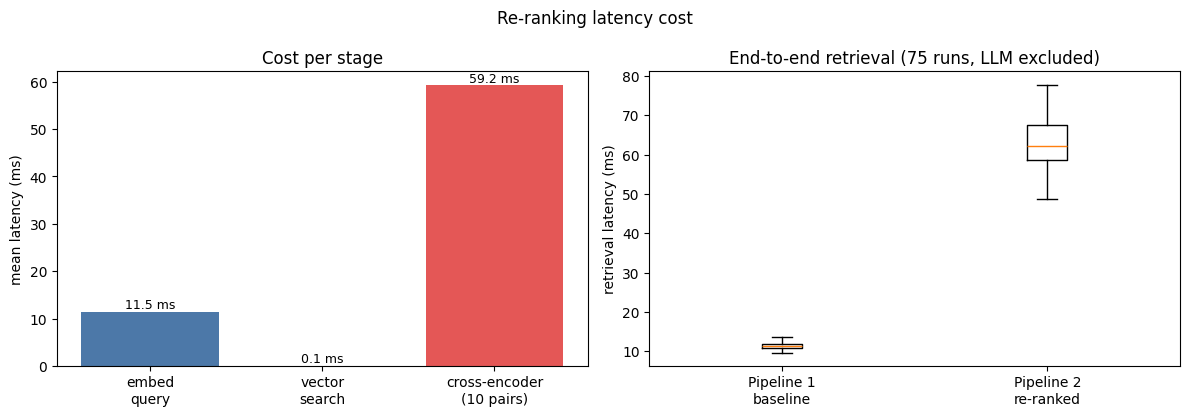

In [18]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

stages = ["embed\nquery", "vector\nsearch", "cross-encoder\n(10 pairs)"]
means = [statistics.mean(raw["embed"]), statistics.mean(raw["search"]),
         statistics.mean(raw["cross"])]
ax1.bar(stages, means, color=["#4C78A8", "#4C78A8", "#E45756"])
ax1.set_ylabel("mean latency (ms)")
ax1.set_title("Cost per stage")
for i, v in enumerate(means):
    ax1.text(i, v, f"{v:.1f} ms", ha="center", va="bottom", fontsize=9)

ax2.boxplot([raw["base"], raw["rr"]],
            tick_labels=["Pipeline 1\nbaseline", "Pipeline 2\nre-ranked"],
            showfliers=False)
ax2.set_ylabel("retrieval latency (ms)")
ax2.set_title(f"End-to-end retrieval ({n} runs, LLM excluded)")

fig.suptitle("Re-ranking latency cost", fontsize=12)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/latency.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Persist everything the report quotes, so the prose and the code agree.
rank_df.to_csv(RESULTS / "rank_analysis.csv")
latency_df.to_csv(RESULTS / "latency.csv")
(RESULTS / "summary.json").write_text(json.dumps(
    {
        "document": {
            "source": PDF_URL,
            "pages": len(pages),
            "chunks": len(chunks),
            "mean_chunk_chars": round(statistics.mean(lengths), 1),
            "total_chars": sum(lengths),
        },
        "models": {
            "bi_encoder": BI_ENCODER_NAME,
            "cross_encoder": CROSS_ENCODER_NAME,
            "generator": GEMINI_MODEL,
        },
        "retrieval": {
            "top_k_retrieve": TOP_K_RETRIEVE,
            "top_n_context": TOP_N_CONTEXT,
            "queries": len(rank_df),
            "gold_in_top3_baseline": int(rank_df.in_top3_base.sum()),
            "gold_in_top3_reranked": int(rank_df.in_top3_rerank.sum()),
            "rescued": list(rank_df[rank_df.outcome == "rescued"].index),
            "unreachable_by_reranking": list(
                rank_df[rank_df.outcome == "unreachable"].index),
        },
        "latency_ms": {
            "embed_query_mean": round(statistics.mean(raw["embed"]), 2),
            "vector_search_mean": round(statistics.mean(raw["search"]), 2),
            "cross_encode_10_pairs_mean": round(statistics.mean(raw["cross"]), 2),
            "pipeline1_retrieval_mean": round(statistics.mean(raw["base"]), 2),
            "pipeline2_retrieval_mean": round(statistics.mean(raw["rr"]), 2),
            "overhead_multiple": round(overhead, 2),
        },
    },
    indent=1,
))
print("wrote:", *(p.name for p in sorted(RESULTS.iterdir())))

wrote: answers.json latency.csv latency.json rank_analysis.csv rank_analysis.json summary.json


## 8. Why not run the cross-encoder over everything?

The measurement above answers this directly. Scoring 10 pairs takes the time
printed in the latency table; the cost is **one transformer forward pass per
(query, chunk) pair**, and it is linear in the number of pairs. Extrapolating
to all 1,118 chunks of this one small rulebook — and then to a realistic
corpus — is the arithmetic in the cell below.

The structural reason is that a cross-encoder produces **no reusable
artefact**. A bi-encoder's chunk vectors are query-independent: embed the
corpus once, then every future query is a dot product against a matrix that is
already in memory, and an ANN index can avoid even touching most of it. A
cross-encoder score exists only for a specific pair, so nothing can be
precomputed, nothing cached, and no index can prune the candidate set — the
work scales with corpus size on *every* query.

Hence the two-stage shape: a cheap, recall-oriented bi-encoder narrows
thousands of chunks to ten, and an expensive, precision-oriented cross-encoder
orders those ten. The ceiling is visible in the `unreachable` rows of the rank
table: anything the first stage fails to surface, the second stage can never
recover.

In [20]:
per_pair_ms = statistics.mean(raw["cross"]) / TOP_K_RETRIEVE
print(f"measured cross-encoder cost: {per_pair_ms:.1f} ms per (query, chunk) pair\n")

for label, n_chunks in [
    ("this rulebook", len(chunks)),
    ("a 10k-chunk corpus", 10_000),
    ("a 1M-chunk corpus", 1_000_000),
]:
    full = n_chunks * per_pair_ms / 1000
    two_stage = statistics.mean(raw["rr"]) / 1000
    print(f"{label:22} ({n_chunks:>9,} chunks): "
          f"cross-encode everything = {full:>10,.1f} s per query   |   "
          f"two-stage = {two_stage:.3f} s   "
          f"({full / two_stage:,.0f}x)")

measured cross-encoder cost: 5.9 ms per (query, chunk) pair

this rulebook          (    1,119 chunks): cross-encode everything =        6.6 s per query   |   two-stage = 0.071 s   (94x)
a 10k-chunk corpus     (   10,000 chunks): cross-encode everything =       59.2 s per query   |   two-stage = 0.071 s   (837x)
a 1M-chunk corpus      (1,000,000 chunks): cross-encode everything =    5,919.8 s per query   |   two-stage = 0.071 s   (83,697x)
